# 🚦 RoadSafe AI — Intelligent Road Safety & Accident Risk Analysis
**ML • Deep Learning (YOLO/CV) • NLP • Integrated Dashboard-style Notebook**

This notebook implements the modules described in the RoadSafe AI proposal, using the
Kaggle dataset **"US 2020 Traffic Accidents"** (jonbown/us-2020-traffic-accidents):

- **A. Machine Learning** — train & compare Logistic Regression, Random Forest and XGBoost
  to classify accident **risk severity** (Low / Medium / High), pick the best model.
- **B. NLP Accident Report Analyzer** — extract structured info (weather, road condition,
  visibility, etc.) from the free-text `Description` column, and train a text classifier.
- **C. Computer Vision** — YOLOv8 pretrained object detector to detect vehicles/pedestrians
  in an uploaded road image (the tabular dataset has no images, so this module works on any
  road photo you upload).
- **D. Integration** — combine the three outputs into one simple risk summary.

Every data-dependent cell is written defensively (it inspects the columns that are actually
present) so it should run without column-name errors even if the exact CSV export differs
slightly from what's expected.

**How to use in Colab:** Run cells top to bottom. Cell 2 lets you either (a) use the Kaggle
API, or (b) upload the CSV manually / load it from Google Drive.


## 1. Setup — install & import libraries

In [1]:
!pip -q install kaggle scikit-learn xgboost spacy ultralytics --upgrade
!python -m spacy download en_core_web_sm -q


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 64.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 55.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.7/88.7 kB 8.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 100.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import os
import re
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              classification_report, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
RANDOM_STATE = 42
print('Libraries loaded.')


Libraries loaded.


## 2. Get the dataset

Pick **ONE** of the two options below.

### Option A — Kaggle API (recommended, fastest in Colab)
1. On kaggle.com go to *Account → Create New API Token* → this downloads `kaggle.json`.
2. Run the cell, upload `kaggle.json` when prompted.


### Option B — Manual upload or Google Drive
Use this instead of Option A if you already have the CSV(s) locally or in Drive.


In [3]:
# --- OPTION B1: upload CSV(s) directly ---
# from google.colab import files
# uploaded = files.upload()
# for fname in uploaded:
#     with open(DATA_DIR / fname, 'wb') as f:
#         f.write(uploaded[fname])

# --- OPTION B2: load from Google Drive ---
from google.colab import drive
drive.mount('/content/drive')
DATA_DIR = Path('/content/drive/MyDrive/Dataset of Roadsafe ai')  # <-- change to your folder



Mounted at /content/drive


## 3. Load the data

This dataset is **NHTSA FARS relational data**, not a single flat CSV: it ships as three
separate table *types*, each repeated per year —

- `acc_YY.csv`  — one row per **accident** (weather, light/road conditions, location, time, etc.)
- `pers_YY.csv` — one row per **person** involved (age, sex, `INJ_SEV` injury severity, seat pos, restraint use, etc.)
- `veh_YY.csv`  — one row per **vehicle** involved (make, model, body type, rollover, etc.)

They're linked by `CASENUM` (unique *within* a year, so we key on year+CASENUM). The cell below:
1. Reads every file with an encoding fallback (`utf-8` → `cp1252` → `latin-1`) — this fixes the
   `UnicodeDecodeError`, which happens because FARS exports are usually Windows-1252, not UTF-8.
2. Detects the `acc_` / `pers_` / `veh_` prefix from each filename and tags each row with its `YEAR`.
3. Concatenates each table type across the five years.
4. Merges accident-level + person-level tables on `(YEAR, CASENUM)`, so the resulting `df` has
   both the environmental context (from `acc_*`) and the injury outcome (`INJ_SEV`, from `pers_*`)
   on every row — this is what the ML/NLP modules below need.

If your files don't follow this acc/pers/veh naming (e.g. you swapped in the plain Kaggle
"US Accidents" CSV instead), it automatically falls back to the original single/concat logic.

In [4]:
import re

CSV_FILES = list(DATA_DIR.glob('*.csv'))
if not CSV_FILES:
    raise FileNotFoundError(
        f'No CSV found in {DATA_DIR}. Run the Kaggle-API cell above, or upload the CSV(s) '
        'via Option B, or point DATA_DIR at the right Google Drive folder.'
    )

print(f'Found {len(CSV_FILES)} CSV file(s):')
for f in CSV_FILES:
    print(' -', f.name)

def read_csv_safe(path, **kwargs):
    """Read a CSV trying utf-8 first, then falling back to cp1252/latin-1
    (FARS/government exports are commonly Windows-1252, which trips utf-8 decoding)."""
    for enc in ('utf-8', 'cp1252', 'latin-1'):
        try:
            return pd.read_csv(path, low_memory=False, encoding=enc, **kwargs)
        except UnicodeDecodeError:
            continue
    # latin-1 maps every byte, so this line should never actually be reached
    return pd.read_csv(path, low_memory=False, encoding='latin-1', **kwargs)

# --- Detect FARS-style acc_/pers_/veh_ files -------------------------------------------------
FARS_PATTERN = re.compile(r'^(acc|pers|veh)_?(\d{2,4})', re.IGNORECASE)
fars_groups = {'acc': [], 'pers': [], 'veh': []}
is_fars = True

for f in CSV_FILES:
    m = FARS_PATTERN.match(f.stem)
    if not m:
        is_fars = False
        break
    table_type, yr = m.group(1).lower(), m.group(2)
    year = int(yr) if len(yr) == 4 else (2000 + int(yr) if int(yr) < 50 else 1900 + int(yr))
    fars_groups[table_type].append((year, f))

if is_fars and fars_groups['acc'] and fars_groups['pers']:
    print('\nDetected FARS-style acc_/pers_/veh_ files -> loading & merging by year.')

    def load_table_group(files_with_years):
        parts = []
        for year, path in sorted(files_with_years):
            part = read_csv_safe(path)
            part.columns = [str(c).strip() for c in part.columns]
            part['YEAR'] = year
            parts.append(part)
        return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame()

    acc_df = load_table_group(fars_groups['acc'])
    pers_df = load_table_group(fars_groups['pers'])
    veh_df = load_table_group(fars_groups['veh']) if fars_groups['veh'] else pd.DataFrame()

    print('acc_df:', acc_df.shape, ' pers_df:', pers_df.shape, ' veh_df:', veh_df.shape)

    # CASENUM is only unique within a given year, so merge on (YEAR, CASENUM).
    # acc_df has one row per accident; suffix its columns so nothing clashes with pers_df.
    acc_cols_keep = [c for c in acc_df.columns if c not in ('YEAR', 'CASENUM')]
    df = pers_df.merge(
        acc_df[['YEAR', 'CASENUM'] + acc_cols_keep],
        on=['YEAR', 'CASENUM'], how='left', suffixes=('', '_ACC')
    )
    print('Merged person+accident shape:', df.shape)
else:
    # --- Fallback: original single-file / same-schema-concat logic ---------------------------
    print('\nNot FARS-style filenames -> using generic single/concat loader.')
    if len(CSV_FILES) > 1:
        try:
            dfs = [read_csv_safe(f) for f in CSV_FILES]
            same_cols = all(set(d.columns) == set(dfs[0].columns) for d in dfs)
            if same_cols:
                df = pd.concat(dfs, ignore_index=True)
                print('Multiple compatible CSVs found -> concatenated.')
            else:
                CSV_PATH = max(CSV_FILES, key=lambda p: p.stat().st_size)
                df = read_csv_safe(CSV_PATH)
                print(f'CSVs have different schemas -> using the largest file: {CSV_PATH.name}')
        except Exception as e:
            CSV_PATH = max(CSV_FILES, key=lambda p: p.stat().st_size)
            df = read_csv_safe(CSV_PATH)
            print(f'Concat failed ({e}) -> using the largest file: {CSV_PATH.name}')
    else:
        CSV_PATH = CSV_FILES[0]
        df = read_csv_safe(CSV_PATH)
        print('Using:', CSV_PATH)

df.columns = [str(c).strip() for c in df.columns]
print('\nFinal shape:', df.shape)
display(df.head())
print(df.dtypes)


Found 15 CSV file(s):
 - acc_16.csv
 - acc_17.csv
 - acc_18.csv
 - acc_19.csv
 - acc_20.csv
 - pers_16.csv
 - pers_17.csv
 - pers_18.csv
 - pers_19.csv
 - pers_20.csv
 - veh_16.csv
 - veh_17.csv
 - veh_18.csv
 - veh_19.csv
 - veh_20.csv

Detected FARS-style acc_/pers_/veh_ files -> loading & merging by year.
acc_df: (259077, 90)  pers_df: (644274, 118)  veh_df: (457314, 185)
Merged person+accident shape: (644274, 206)

Final shape: (644274, 206)


,CASENUM,VE_FORMS,VEH_NO,PER_NO,PSU,PJ,STRATUM,STR_VEH,MONTH,HOUR,...,MINUTE_IMNAME,EVENT1_IMNAME,MANCOL_IMNAME,RELJCT2_IMNAME,LGTCON_IMNAME,WEATHR_IMNAME,MAXSEV_IMNAME,NO_INJ_IMNAME,ALCHL_IMNAME,RELJCT1_IMNAME
0,201600014311,2,1,1,44,388,9,0,1,12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,201600014311,2,2,1,44,388,9,0,1,12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,201600014315,2,1,1,44,388,8,0,1,19,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,201600014315,2,2,1,44,388,8,0,1,19,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,201600014315,2,2,2,44,388,8,0,1,19,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


CASENUM            int64
VE_FORMS           int64
VEH_NO             int64
PER_NO             int64
PSU                int64
                   ...  
WEATHR_IMNAME     object
MAXSEV_IMNAME     object
NO_INJ_IMNAME     object
ALCHL_IMNAME      object
RELJCT1_IMNAME    object
Length: 206, dtype: object


## 4. Clean data & detect the target (severity/risk) column

This looks for a severity-style column under several possible names (`Severity`,
`INJ_SEV`, etc.). If your export truly has none, it falls back to letting you set
`SEVERITY_COL` manually.

In [5]:
def find_column(columns, exact_names=None, contains=None):
    exact_names = exact_names or []
    contains = contains or []
    lower_map = {c.lower(): c for c in columns}
    for name in exact_names:
        if name.lower() in lower_map:
            return lower_map[name.lower()]
    for c in columns:
        cl = c.lower()
        if any(tok in cl for tok in contains):
            return c
    return None

SEVERITY_COL = find_column(
    df.columns,
    exact_names=['Severity', 'Injury_Severity', 'Injury Severity', 'INJ_SEV'],
    contains=['severity', 'sev']
)

if SEVERITY_COL is None:
    raise ValueError(
        f'Could not auto-detect a severity column. Available columns:\n{df.columns.tolist()}\n'
        'Set SEVERITY_COL manually to the right column name and re-run.'
    )

print('Severity column detected:', SEVERITY_COL)
print(df[SEVERITY_COL].value_counts(dropna=False).sort_index())


Severity column detected: INJ_SEV
INJ_SEV
0    429574
1     95761
2     57299
3     32556
4      5587
5      1883
6        19
9     21595
Name: count, dtype: int64


In [6]:
# Map the (possibly numeric-coded) severity column onto Low / Medium / High risk classes.
# This is intentionally generic so it works whether Severity is 1-4 (Kaggle-style) or a
# wider numeric code range.

def map_to_risk(value, min_v, max_v):
    if pd.isna(value):
        return np.nan
    span = max_v - min_v
    if span == 0:
        return 'Medium'
    pct = (value - min_v) / span
    if pct <= 1/3:
        return 'Low'
    elif pct <= 2/3:
        return 'Medium'
    else:
        return 'High'

sev_numeric = pd.to_numeric(df[SEVERITY_COL], errors='coerce')
if sev_numeric.notna().mean() > 0.9:
    # numeric severity -> bucket into 3 risk classes
    min_v, max_v = sev_numeric.min(), sev_numeric.max()
    df['Risk_Level'] = sev_numeric.apply(lambda v: map_to_risk(v, min_v, max_v))
else:
    # already categorical text -> use as-is
    df['Risk_Level'] = df[SEVERITY_COL].astype(str)

df = df.dropna(subset=['Risk_Level'])
print(df['Risk_Level'].value_counts())


Risk_Level
Low       615190
High       21595
Medium      7489
Name: count, dtype: int64


## 5. Exploratory Data Analysis

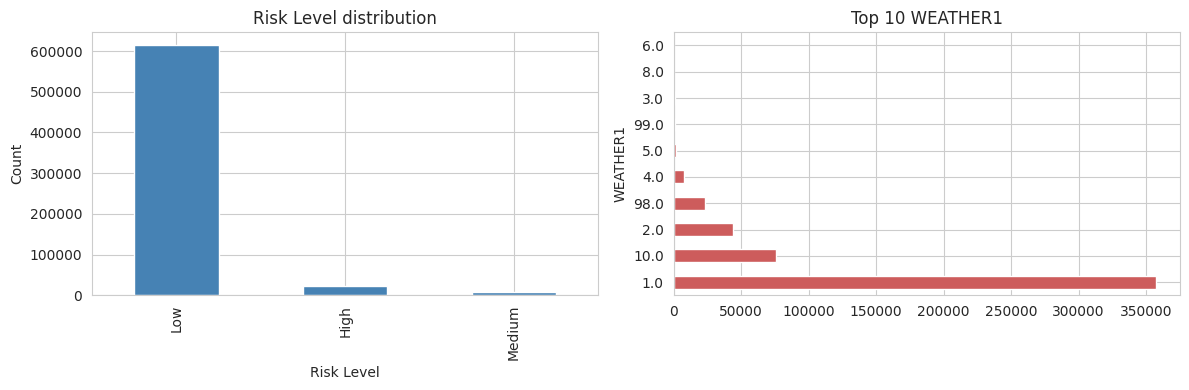

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['Risk_Level'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue')
axes[0].set_title('Risk Level distribution')
axes[0].set_xlabel('Risk Level')
axes[0].set_ylabel('Count')

WEATHER_COL = find_column(df.columns, contains=['weather'])
if WEATHER_COL:
    df[WEATHER_COL].value_counts().head(10).plot(kind='barh', ax=axes[1], color='indianred')
    axes[1].set_title(f'Top 10 {WEATHER_COL}')
else:
    axes[1].axis('off')
    axes[1].text(0.5, 0.5, 'No weather column found', ha='center')

plt.tight_layout()
plt.show()


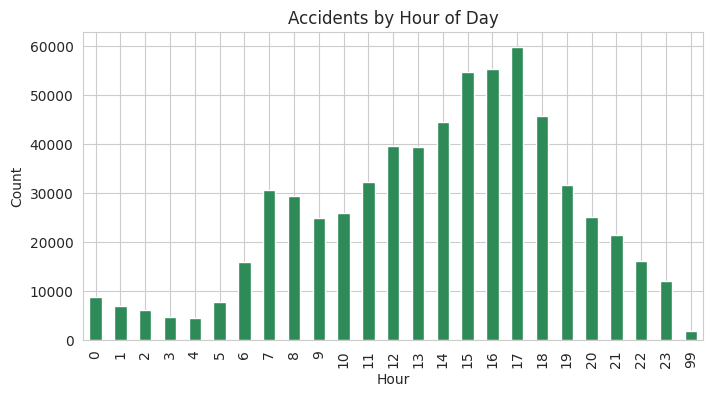

In [8]:
TIME_COL = find_column(df.columns, exact_names=['Start_Time', 'Hour'], contains=['start_time', 'hour', 'time'])
if TIME_COL:
    try:
        if not pd.api.types.is_numeric_dtype(df[TIME_COL]):
            hours = pd.to_datetime(df[TIME_COL], errors='coerce').dt.hour
        else:
            hours = df[TIME_COL]
        plt.figure(figsize=(8, 4))
        hours.value_counts().sort_index().plot(kind='bar', color='seagreen')
        plt.title('Accidents by Hour of Day')
        plt.xlabel('Hour')
        plt.ylabel('Count')
        plt.show()
    except Exception as e:
        print('Could not parse a time-of-day feature:', e)
else:
    print('No time/hour column found — skipping this plot.')


## 6. Module B — Machine Learning risk classification
Trains Logistic Regression, Random Forest and XGBoost on the available structured features
and compares them on accuracy / precision / recall / F1. Only columns that exist and look
usable as features are picked automatically — edit `CANDIDATE_FEATURES` if you want to force
a specific set.

In [9]:
# Auto-pick a reasonable set of feature columns (exclude obvious IDs/free text/targets).
EXCLUDE_PATTERNS = ['id', 'description', 'unnamed', 'index', 'casenum', 'st_case',
                     'veh_no', 'per_no', 'stratum', 'str_veh', 'psu', '_acc']
DESC_COL = find_column(df.columns, contains=['description'])

candidate_cols = [
    c for c in df.columns
    if c not in [SEVERITY_COL, 'Risk_Level']
    and not any(p in c.lower() for p in EXCLUDE_PATTERNS)
]

# Keep a manageable number of features: prefer known road-safety signals if present,
# otherwise take the first ~15 remaining columns.
PREFERRED = ['Weather_Condition', 'Visibility(mi)', 'Temperature(F)', 'Humidity(%)',
             'Wind_Speed(mph)', 'Pressure(in)', 'Precipitation(in)', 'Sunrise_Sunset',
             'Road_Condition', 'Traffic_Signal', 'Junction', 'Crossing', 'State', 'City']
feature_cols = [c for c in PREFERRED if c in candidate_cols]
remaining = [c for c in candidate_cols if c not in feature_cols]
feature_cols += remaining[: max(0, 15 - len(feature_cols))]

print(f'Using {len(feature_cols)} feature columns:')
print(feature_cols)

X = df[feature_cols].copy()
y = df['Risk_Level'].copy()

# Subsample for speed if the dataset is very large (tree/boosting models on millions of
# rows can be slow in a free Colab runtime).
MAX_ROWS = 300_000
if len(X) > MAX_ROWS:
    X = X.sample(MAX_ROWS, random_state=RANDOM_STATE)
    y = y.loc[X.index]
    print(f'Subsampled to {MAX_ROWS} rows for training speed.')

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)


Using 15 feature columns:
['VE_FORMS', 'PJ', 'MONTH', 'HOUR', 'MINUTE', 'HARM_EV', 'MAN_COLL', 'SCH_BUS', 'MAKE', 'BODY_TYP', 'MOD_YEAR', 'MAK_MOD', 'TOW_VEH', 'SPEC_USE', 'EMER_USE']
Subsampled to 300000 rows for training speed.
Numeric features: ['VE_FORMS', 'PJ', 'MONTH', 'HOUR', 'MINUTE', 'HARM_EV', 'MAN_COLL', 'SCH_BUS', 'MAKE', 'BODY_TYP', 'MOD_YEAR', 'MAK_MOD', 'TOW_VEH', 'SPEC_USE', 'EMER_USE']
Categorical features: []


In [10]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', max_categories=30, sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=RANDOM_STATE, stratify=y_encoded
)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=15,
                                             class_weight='balanced', random_state=RANDOM_STATE,
                                             n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                              eval_metric='mlogloss', random_state=RANDOM_STATE, n_jobs=-1)
}

results = []
fitted_pipelines = {}

for name, model in models.items():
    pipe = Pipeline(steps=[('preprocess', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    acc = accuracy_score(y_test, preds)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, preds, average='weighted', zero_division=0)
    results.append({'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-score': f1})
    fitted_pipelines[name] = pipe
    print(f'{name}: accuracy={acc:.3f} f1={f1:.3f}')

results_df = pd.DataFrame(results).sort_values('F1-score', ascending=False).reset_index(drop=True)
display(results_df)

BEST_MODEL_NAME = results_df.iloc[0]['Model']
best_pipeline = fitted_pipelines[BEST_MODEL_NAME]
print(f'\n>>> Best performing model: {BEST_MODEL_NAME}')


Logistic Regression: accuracy=0.685 f1=0.792
Random Forest: accuracy=0.847 f1=0.895
XGBoost: accuracy=0.966 f1=0.959


,Model,Accuracy,Precision,Recall,F1-score
0,XGBoost,0.966350,0.958003,0.966350,0.958692
1,Random Forest,0.846950,0.957351,0.846950,0.895251
2,Logistic Regression,0.685067,0.954007,0.685067,0.791563



>>> Best performing model: XGBoost


              precision    recall  f1-score   support

        High       0.77      0.49      0.60      2020
         Low       0.97      0.99      0.98     57290
      Medium       0.44      0.01      0.02       690

    accuracy                           0.97     60000
   macro avg       0.73      0.50      0.54     60000
weighted avg       0.96      0.97      0.96     60000



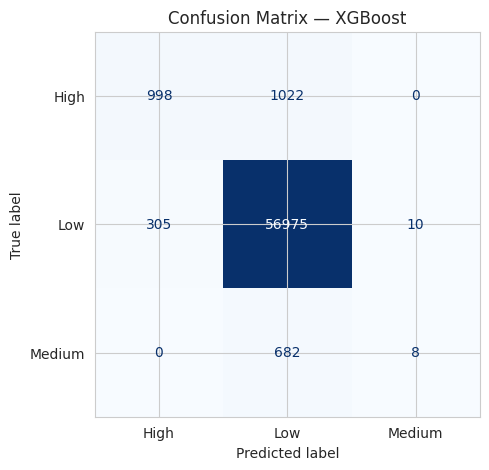

In [11]:
# Detailed report + confusion matrix for the best model
best_preds = best_pipeline.predict(X_test)
print(classification_report(y_test, best_preds, target_names=le.classes_))

cm = confusion_matrix(y_test, best_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title(f'Confusion Matrix — {BEST_MODEL_NAME}')
plt.show()


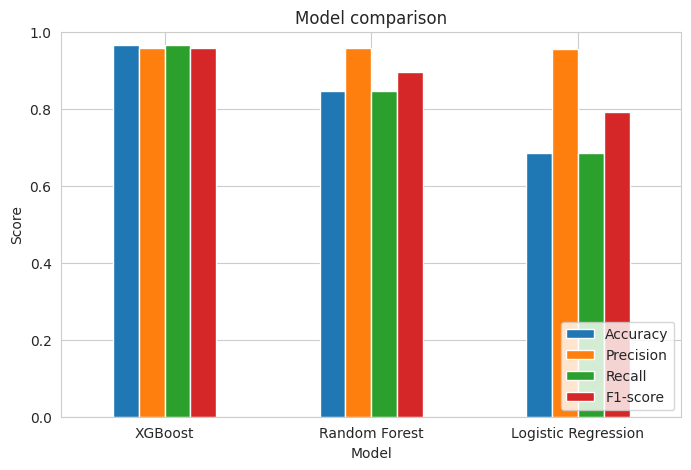

In [12]:
results_df.set_index('Model')[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot(
    kind='bar', figsize=(8, 5), rot=0
)
plt.title('Model comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.show()


## 7. Module A — Computer Vision (YOLOv8 object detection)
The tabular dataset has no images, so this module runs on any road photo **you upload**,
detecting vehicles and pedestrians and computing a simple traffic-density indicator — exactly
as described in the proposal's Computer Vision module.

In [16]:
from ultralytics import YOLO
import cv2

yolo_model = YOLO('yolov8n.pt')  # small, fast pretrained COCO model

ROAD_CLASSES = {'car', 'truck', 'bus', 'motorcycle', 'bicycle', 'person'}

def detect_road_objects(image_path):
    results = yolo_model(image_path, verbose=False)
    result = results[0]
    names = result.names
    counts = {}
    for box in result.boxes:
        cls_id = int(box.cls[0])
        cls_name = names[cls_id]
        if cls_name in ROAD_CLASSES:
            counts[cls_name] = counts.get(cls_name, 0) + 1

    annotated = result.plot()  # BGR numpy array with boxes drawn
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

    total_vehicles = sum(v for k, v in counts.items() if k != 'person')
    if total_vehicles <= 3:
        density = 'Low'
    elif total_vehicles <= 8:
        density = 'Medium'
    else:
        density = 'High'

    return counts, density, annotated_rgb

print('YOLOv8 loaded. Upload an image in the next cell to run detection.')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLOv8 loaded. Upload an image in the next cell to run detection.


Upload a road image (jpg/png) to run vehicle & pedestrian detection...


Saving derek-lee-C031beKcwdQ-unsplash.jpg to derek-lee-C031beKcwdQ-unsplash (1).jpg


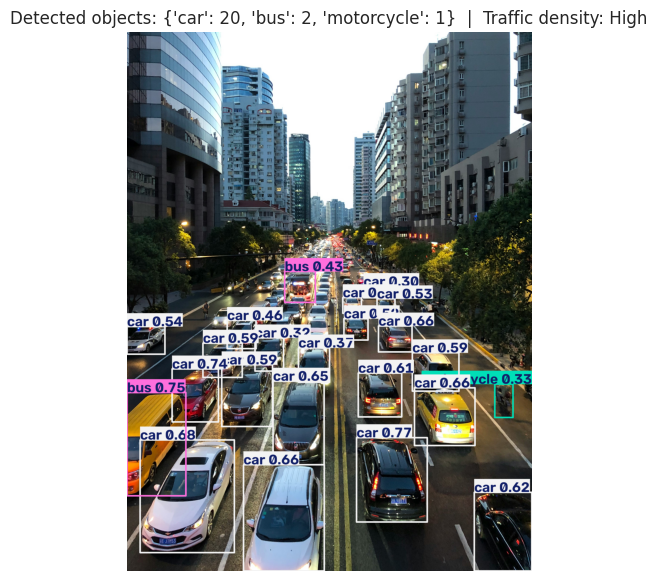

Object counts: {'car': 20, 'bus': 2, 'motorcycle': 1}
Traffic-density indicator: High


In [25]:
from google.colab import files

print('Upload a road image (jpg/png) to run vehicle & pedestrian detection...')
uploaded_img = files.upload()
image_path = next(iter(uploaded_img))

counts, density, annotated_rgb = detect_road_objects(image_path)

plt.figure(figsize=(9, 7))
plt.imshow(annotated_rgb)
plt.axis('off')
plt.title(f'Detected objects: {counts}  |  Traffic density: {density}')
plt.show()

print('Object counts:', counts)
print('Traffic-density indicator:', density)


## 8. Module D — Integrated Risk Analysis
Combines the ML structured-data prediction, the CV traffic-density indicator, and the NLP
description analysis into one summary — a notebook stand-in for the proposal's Streamlit
dashboard.

In [22]:
def integrated_risk_summary(structured_row=None, description_text=None, image_path=None):
    summary = {}

    # ML structured prediction
    if structured_row is not None:
        row_df = pd.DataFrame([structured_row])[feature_cols]
        ml_pred_encoded = best_pipeline.predict(row_df)[0]
        summary['ml_risk_prediction'] = le.inverse_transform([ml_pred_encoded])[0]

    # NLP extraction
    if description_text:
        summary['nlp_extracted_info'] = extract_accident_info(description_text)

    # CV traffic density
    if image_path:
        counts, density, _ = detect_road_objects(image_path)
        summary['cv_object_counts'] = counts
        summary['cv_traffic_density'] = density

    return summary

# Example: reuse one real row from the test set for the ML part, the uploaded image for CV,
# and a sample description for NLP.
example_row = X_test.iloc[0].to_dict()
example_summary = integrated_risk_summary(
    structured_row=example_row,
    description_text=your_report,
    image_path=image_path if 'image_path' in dir() else None
)

print(json.dumps(example_summary, indent=2, default=str))


{
  "ml_risk_prediction": "Low",
  "nlp_extracted_info": {
    "weather_mentions": [
      "rain",
      "fog"
    ],
    "road_condition_mentions": [
      "wet"
    ],
    "vehicles_mentioned": [
      "car"
    ],
    "locations_mentioned": []
  },
  "cv_object_counts": {
    "car": 20,
    "bus": 2,
    "motorcycle": 1
  },
  "cv_traffic_density": "High"
}


## 9. Conclusion & next steps

- **Best-performing ML model:** printed in Section 6 above (`BEST_MODEL_NAME`) — this is the
  model you'd wire into the Streamlit "Accident Risk" screen.
- **NLP module** extracts weather / road-condition / vehicle mentions and (when a description
  column exists) also predicts risk directly from free text.
- **CV module** uses a pretrained YOLOv8 model — no training needed for the 7-day timeline;
  swap in a fine-tuned model later if you have labeled road-scene data.
- To turn this into the actual Streamlit app from the proposal, save `best_pipeline`,
  `tfidf`/`text_clf`, and `yolo_model` with `joblib`/`ultralytics` export, then load them in
  `app.py` behind the four screens (Dashboard, Traffic Vision, Accident Risk, Accident Report,
  Model Performance).


In [23]:
import joblib

joblib.dump(best_pipeline, 'best_risk_model.joblib')
joblib.dump(le, 'risk_label_encoder.joblib')
if DESC_COL:
    joblib.dump(tfidf, 'tfidf_vectorizer.joblib')
    joblib.dump(text_clf, 'text_risk_model.joblib')

print('Saved model artifacts for reuse in a Streamlit app:')
!ls -la *.joblib


Saved model artifacts for reuse in a Streamlit app:
-rw-r--r-- 1 root root 3413177 Sep 22 10:24 best_risk_model.joblib
-rw-r--r-- 1 root root     495 Sep 22 10:24 risk_label_encoder.joblib


In [26]:
from google.colab import files

for fname in ['best_risk_model.joblib', 'risk_label_encoder.joblib']:
    files.download(fname)

# only exists if your dataset had a description column (see earlier NLP note)
import os
if os.path.exists('tfidf_vectorizer.joblib'):
    files.download('tfidf_vectorizer.joblib')
if os.path.exists('text_risk_model.joblib'):
    files.download('text_risk_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>